In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

In [3]:
df = pd.read_csv("Data/credit_card_fraud_detection_2026.csv")

# Checking how clean the data is

In [4]:
df.shape

(100000, 43)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  str    
 1   customer_id                  100000 non-null  str    
 2   card_id                      100000 non-null  str    
 3   merchant_id                  100000 non-null  str    
 4   transaction_datetime         100000 non-null  str    
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  str    
 7   merchant_country             100000 non-null  str    
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  str    
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  str    
 13  customer_st

In [6]:
feature_names = df.columns.tolist()

for col in feature_names:
    sum_of_nan = df[col].isna().sum()
    if sum_of_nan > 0:
        print(f"{col} column has {df[col].isna().sum()} nan's \n")

browser column has 41709 nan's 



<h1> "Browser" is the only col with missing values </h1>

In [7]:
df['browser'].value_counts()

browser
Chrome     20359
Safari     12841
App        12759
Firefox     5448
Edge        4544
Other       2340
Name: count, dtype: int64

<h1>Browser would depend on the device being used, 'POS Terminal' and 'ATM' dont have browsers</h1>

In [8]:
df['device_type'].value_counts()

device_type
Mobile          37777
POS Terminal    35777
Desktop         20514
ATM              5932
Name: count, dtype: int64

<h1> If device type != Mobile | Desktop, set browser to 'N/A'</h1>

In [9]:
df['browser'] = np.where(
    (df['browser'].isna()) & ((df['device_type'] == 'POS Terminal') | (df['device_type'] == 'ATM')),
    'N/A',
    df['browser']
)

<h1>Nothing should be missing now, this cell shouldnt print anything</h1>

In [10]:
feature_names = df.columns.tolist()

for col in feature_names:
    sum_of_nan = df[col].isna().sum()
    if sum_of_nan > 0:
        print(f"{col} column has {df[col].isna().sum()} nan's \n")

In [11]:
df.shape

(100000, 43)

# Checking out the features

<h1> drop cols that shouldnt matter if a transaction is fraud</h1>

In [12]:
cols_to_drop = ['transaction_id', 'customer_id', 'card_id', 'merchant_id', 'fraud_type', 'fraud_amount_lost']
main_feats = df.drop(columns=cols_to_drop)
main_feats

,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,...,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud
0,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,0,41,Female,PA,...,Online,Mobile,Chrome,0,93.91,39.48,0,0,corporate,0
1,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,1,56,Male,WV,...,In-store,POS Terminal,N/A,0,180.05,134.45,0,0,yahoo,0
2,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,0,43,Male,MN,...,Online,Desktop,Chrome,0,42.00,22.46,0,0,hotmail,0
3,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,0,51,Female,OH,...,ATM,ATM,N/A,0,64.87,29.76,0,0,gmail,0
4,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,1,40,Female,PA,...,In-store,POS Terminal,N/A,0,47.19,18.52,0,0,gmail,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2026-12-31 23:21:36,32.83,Restaurant & Dining,Italy,23,Tuesday,1,48,Female,FL,...,In-store,POS Terminal,N/A,0,96.52,44.55,0,0,gmail,0
99996,2026-12-31 23:26:09,167.72,Electronics & Technology,Spain,23,Tuesday,0,20,Female,UT,...,ATM,ATM,N/A,0,75.74,41.67,0,2,gmail,0
99997,2026-12-31 23:30:16,1031.10,Travel & Airlines,France,23,Tuesday,0,28,Female,NM,...,Mobile App,Mobile,App,0,45.40,35.11,2,4,gmail,1
99998,2026-12-31 23:31:19,81.75,Clothing & Apparel,UK,23,Tuesday,0,56,Male,NE,...,Mobile App,Mobile,App,0,168.24,81.40,0,0,yahoo,0


In [13]:
num_cols = main_feats.select_dtypes(include='number')
num_cols

,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,...,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,is_fraud
0,37.36,2,0,41,709,6630.0,742,2,1,2,...,0,0.398,0,0,0,93.91,39.48,0,0,0
1,50.04,3,1,56,1143,4350.0,602,1,6,6,...,0,0.278,1,1,0,180.05,134.45,0,0,0
2,38.87,3,0,43,601,3950.0,605,4,1,1,...,0,0.925,0,0,0,42.00,22.46,0,0,0
3,46.60,3,0,51,582,13870.0,675,5,0,2,...,1,0.718,0,1,0,64.87,29.76,0,0,0
4,62.13,4,1,40,711,6570.0,743,2,1,2,...,0,1.317,1,0,0,47.19,18.52,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,32.83,23,1,48,19,8490.0,588,3,0,1,...,0,0.340,1,0,0,96.52,44.55,0,0,0
99996,167.72,23,0,20,49,2750.0,479,5,0,1,...,0,2.214,0,1,0,75.74,41.67,0,2,0
99997,1031.10,23,0,28,639,11630.0,712,2,3,4,...,0,22.711,0,0,0,45.40,35.11,2,4,1
99998,81.75,23,0,56,89,5050.0,567,4,0,0,...,0,0.486,0,0,0,168.24,81.40,0,0,0


<h1>drop cols that do not have any meaningful spread</h1>

In [14]:
cols_to_drop = ['card_present', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'is_weekend', 'is_fraud']
num_cols = num_cols.drop(columns=cols_to_drop)
num_cols

,transaction_amount,transaction_hour,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,amount_vs_avg_ratio,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever
0,37.36,2,41,709,6630.0,742,2,1,2,3,88.91,209.94,0.9,13.0,0.3,0.398,93.91,39.48,0,0
1,50.04,3,56,1143,4350.0,602,1,6,6,23,1290.10,1093.31,6.6,5311.8,17.0,0.278,180.05,134.45,0,0
2,38.87,3,43,601,3950.0,605,4,1,1,3,36.27,46.54,4.2,14164.5,53.2,0.925,42.00,22.46,0,0
3,46.60,3,51,582,13870.0,675,5,0,2,3,0.00,134.35,3.0,1119.1,3.6,0.718,64.87,29.76,0,0
4,62.13,4,40,711,6570.0,743,2,1,2,2,38.37,117.74,0.9,6564.5,22.4,1.317,47.19,18.52,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,32.83,23,48,19,8490.0,588,3,0,1,7,0.00,88.90,4.8,11870.8,2.3,0.340,96.52,44.55,0,0
99996,167.72,23,20,49,2750.0,479,5,0,1,19,0.00,75.38,13.1,3630.8,0.2,2.214,75.74,41.67,0,2
99997,1031.10,23,28,639,11630.0,712,2,3,4,7,148.76,194.29,2.4,13186.0,1.4,22.711,45.40,35.11,2,4
99998,81.75,23,56,89,5050.0,567,4,0,0,6,0.00,0.00,0.8,2059.8,14.3,0.486,168.24,81.40,0,0


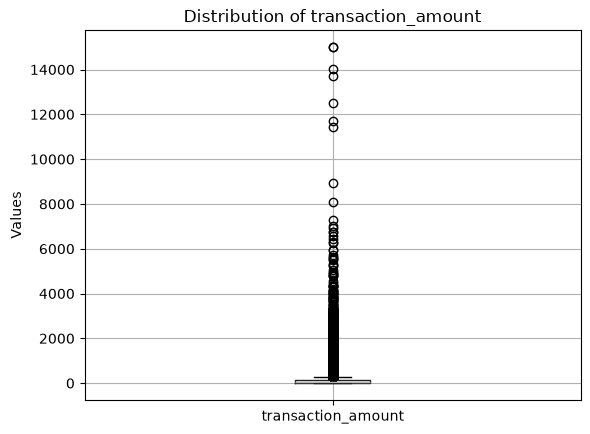

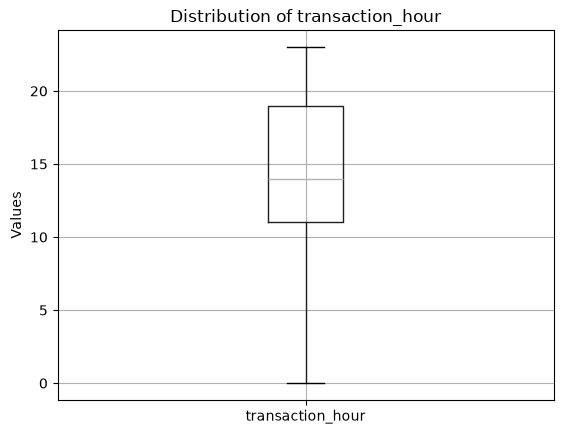

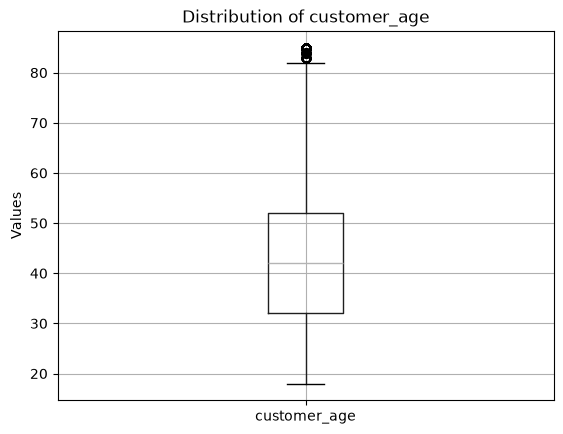

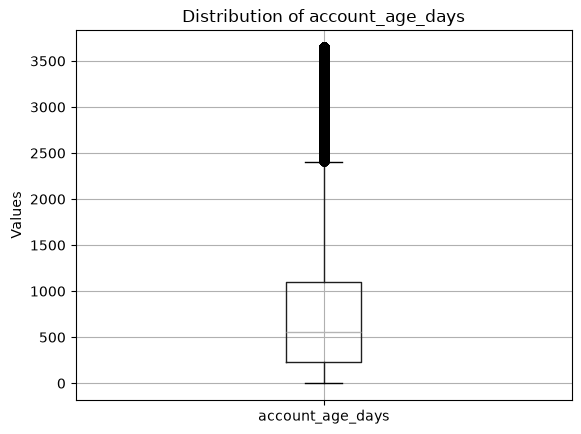

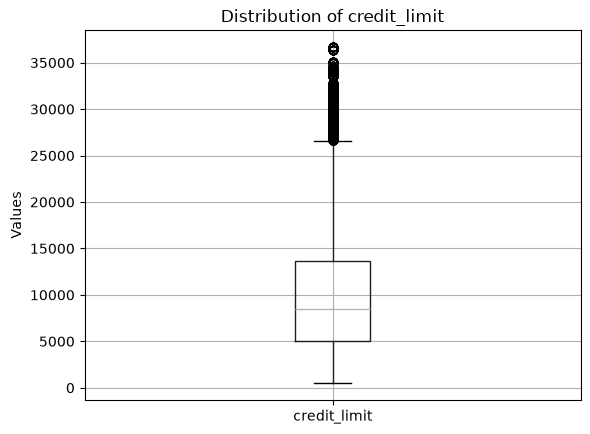

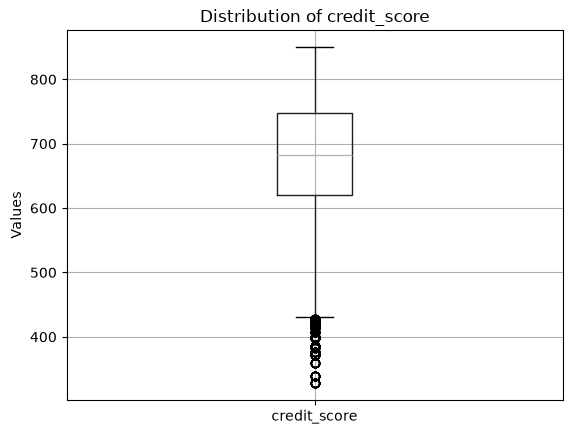

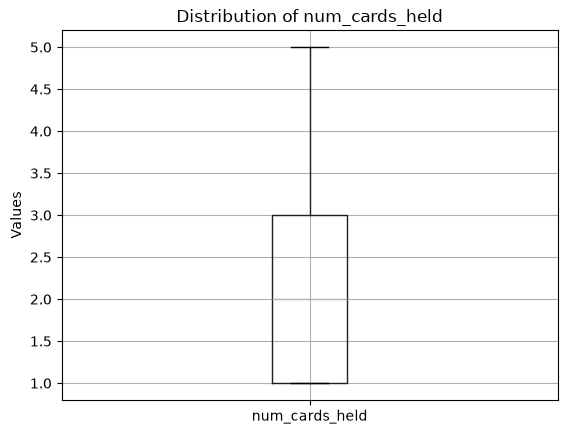

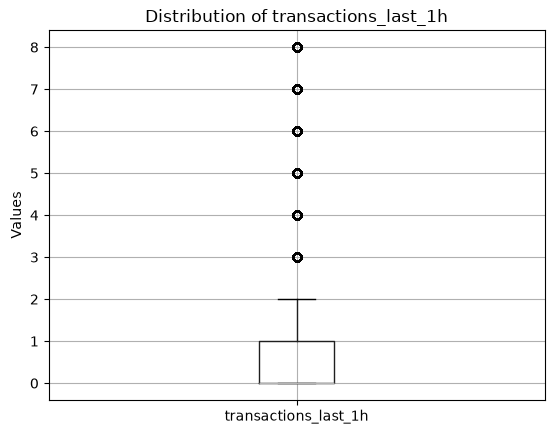

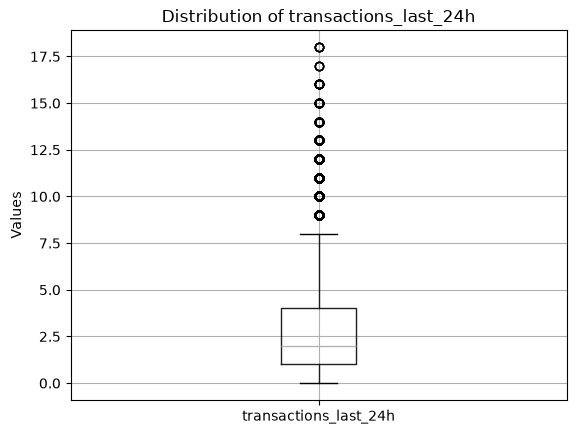

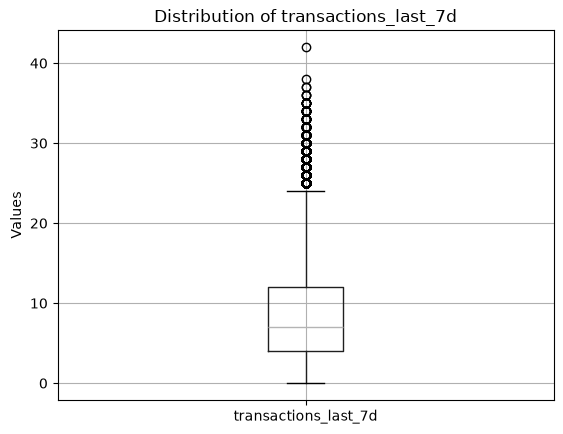

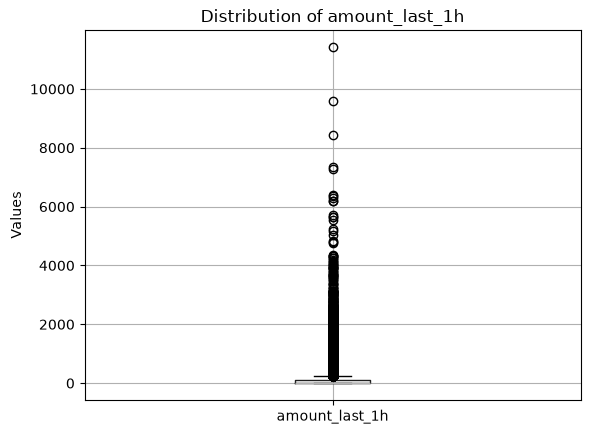

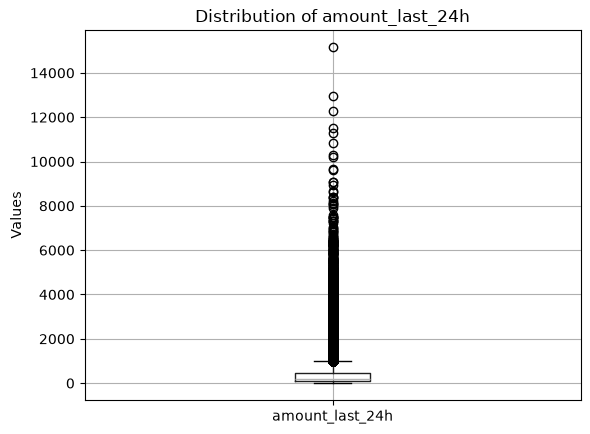

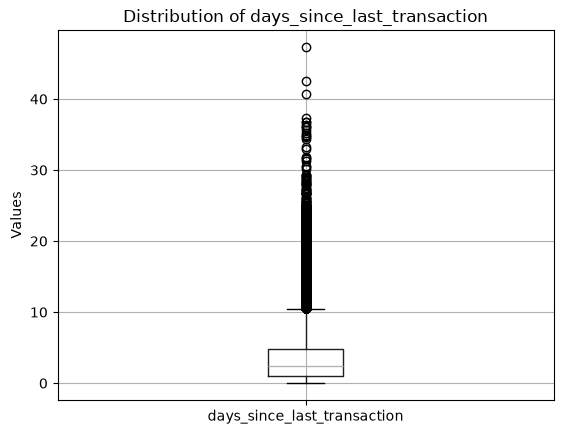

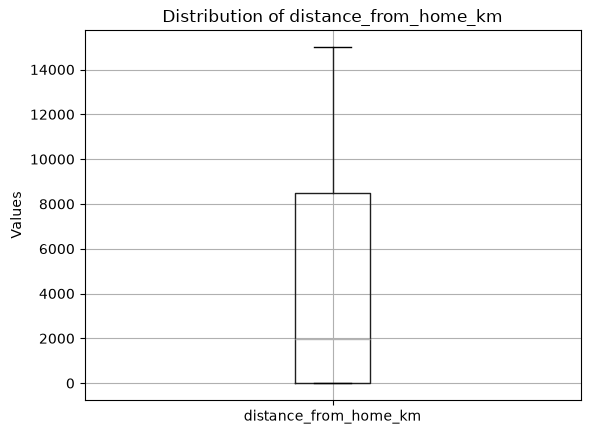

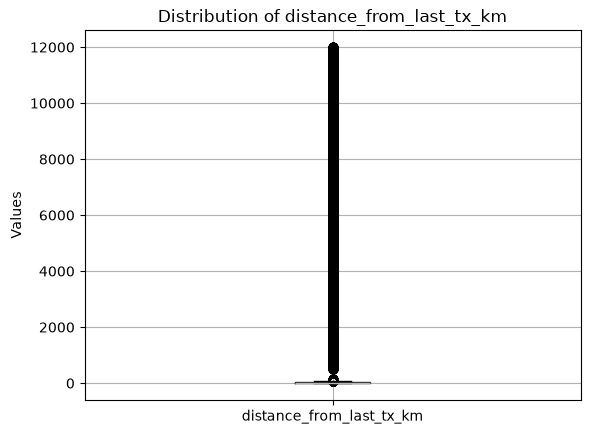

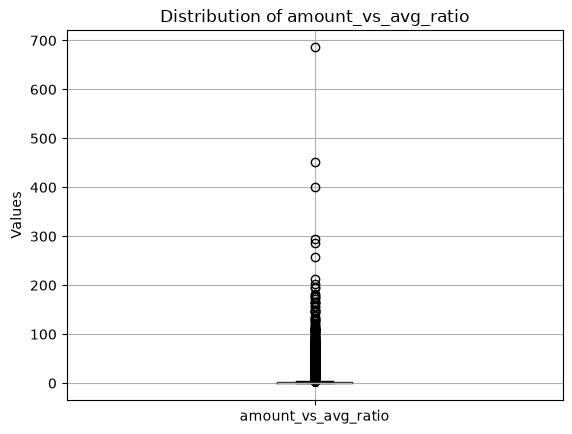

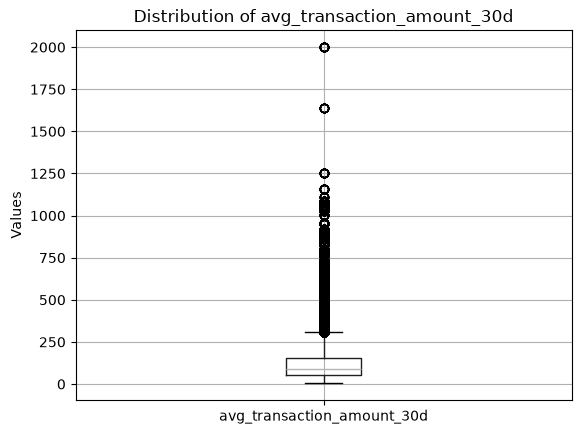

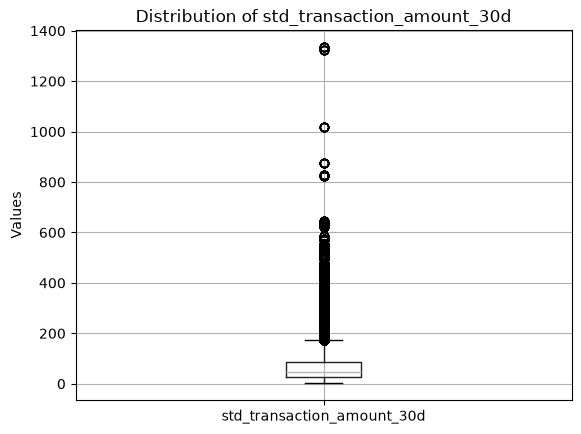

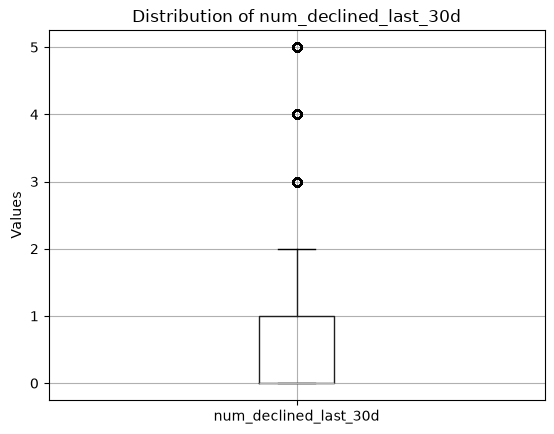

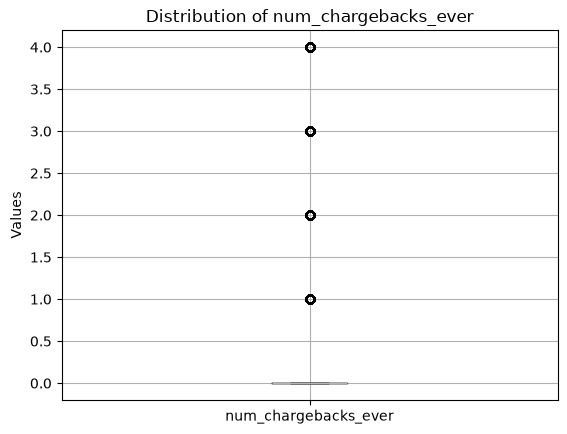

In [15]:
for col in num_cols.columns:
    plt.figure()

    num_cols.boxplot(column=[col])
    plt.title(f'Distribution of {col}')
    plt.ylabel('Values')

    plt.show()


<h1>Hist plots of the cols dropped from the numerical set</h1>

<Figure size 640x480 with 0 Axes>

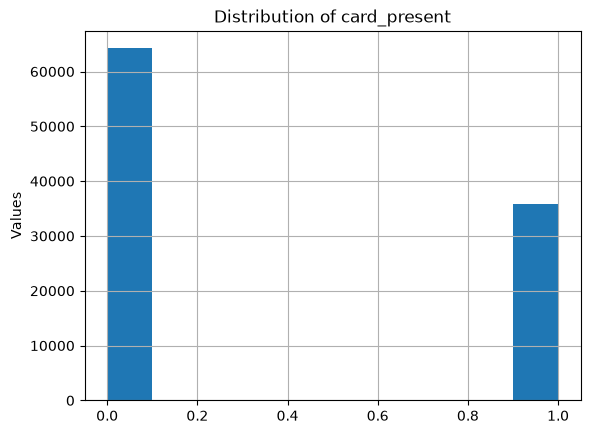

<Figure size 640x480 with 0 Axes>

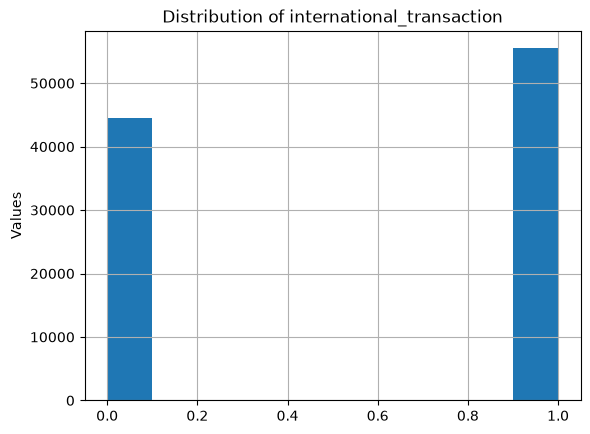

<Figure size 640x480 with 0 Axes>

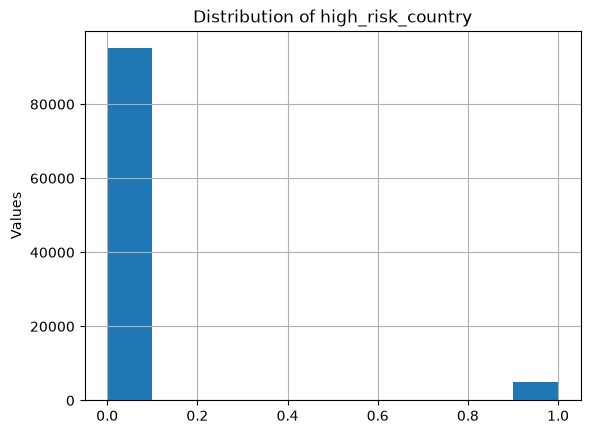

<Figure size 640x480 with 0 Axes>

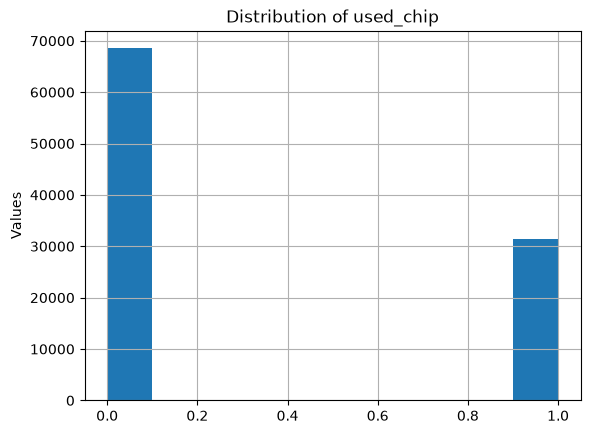

<Figure size 640x480 with 0 Axes>

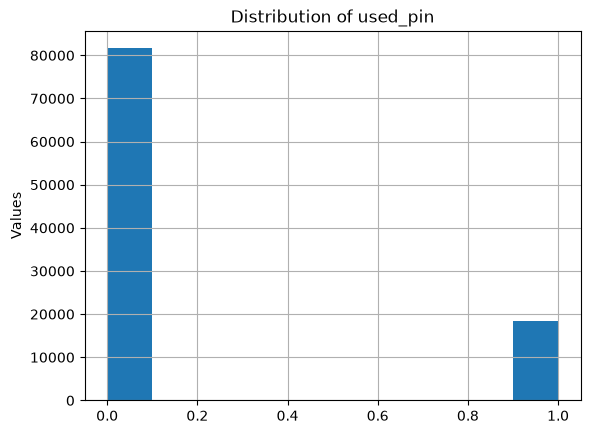

<Figure size 640x480 with 0 Axes>

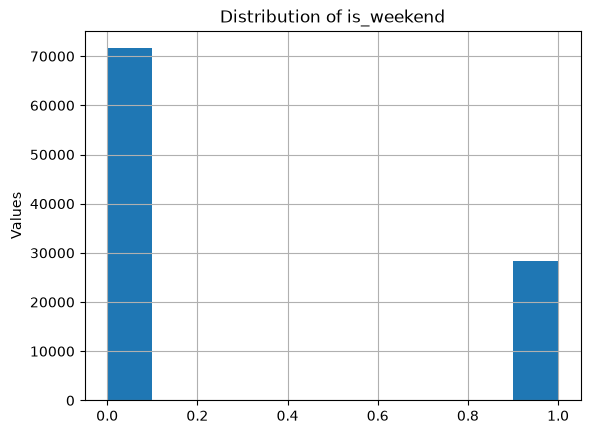

<Figure size 640x480 with 0 Axes>

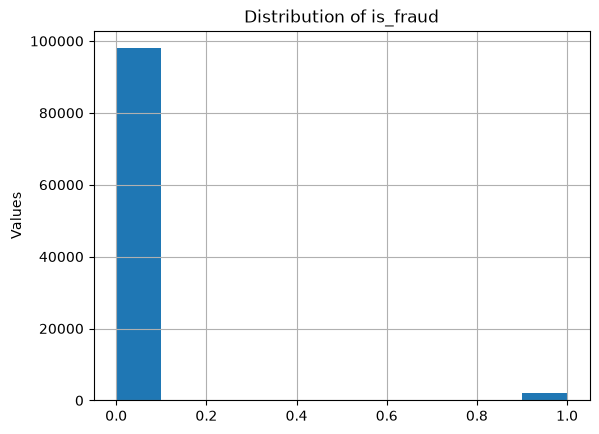

In [16]:
for col in cols_to_drop:
    plt.figure()

    main_feats.hist(column=[col],)
    plt.title(f'Distribution of {col}')
    plt.ylabel('Values')

    plt.show()

In [17]:
cat_cols = main_feats.select_dtypes(include='str')
cat_cols

,transaction_datetime,merchant_category,merchant_country,transaction_day_of_week,customer_gender,customer_state,transaction_channel,device_type,browser,email_domain
0,2026-01-01 02:28:51,Healthcare & Pharmacy,USA,Monday,Female,PA,Online,Mobile,Chrome,corporate
1,2026-01-01 03:15:18,Restaurant & Dining,Germany,Monday,Male,WV,In-store,POS Terminal,N/A,yahoo
2,2026-01-01 03:44:38,Grocery & Supermarket,Australia,Monday,Male,MN,Online,Desktop,Chrome,hotmail
3,2026-01-01 03:53:41,Gas Station,China,Monday,Female,OH,ATM,ATM,N/A,gmail
4,2026-01-01 04:29:08,Clothing & Apparel,UK,Monday,Female,PA,In-store,POS Terminal,N/A,gmail
...,...,...,...,...,...,...,...,...,...,...
99995,2026-12-31 23:21:36,Restaurant & Dining,Italy,Tuesday,Female,FL,In-store,POS Terminal,N/A,gmail
99996,2026-12-31 23:26:09,Electronics & Technology,Spain,Tuesday,Female,UT,ATM,ATM,N/A,gmail
99997,2026-12-31 23:30:16,Travel & Airlines,France,Tuesday,Female,NM,Mobile App,Mobile,App,gmail
99998,2026-12-31 23:31:19,Clothing & Apparel,UK,Tuesday,Male,NE,Mobile App,Mobile,App,yahoo


In [18]:
#Dont want to plot datetime so drop that 
cat_cols = cat_cols.drop(columns='transaction_datetime')

<h1>Abstracting 'merchant_country' column</h1>

In [19]:
cat_cols['merchant_country'].value_counts()

merchant_country
USA             44515
UK               8349
Canada           7238
Germany          5651
Australia        5423
France           4521
Italy            3344
Netherlands      3039
Spain            2849
Brazil           2354
India            2175
Mexico           1921
China            1682
Nigeria          1261
South Africa     1140
Russia           1046
Romania           943
UAE               940
Japan             821
South Korea       788
Name: count, dtype: int64

In [20]:
high_risk_countries = ['USA', 'Mexico', 'India', 'UK', 'Spain']
fraud_source_countries = ['Russia', 'Ukraine', 'Nigeria', 'Romania']

is_highrisk = main_feats['merchant_country'].isin(high_risk_countries) #concat these to main_feats, drop merchant country
is_source = main_feats['merchant_country'].isin(fraud_source_countries)

# Flagging outliers for transactions per merchant categories

In [21]:
cat_cols['merchant_category'].value_counts()

merchant_category
Online Retail                13417
Restaurant & Dining          12736
Grocery & Supermarket        12137
Gas Station                  10885
Healthcare & Pharmacy         7903
Electronics & Technology      6934
Travel & Airlines             6612
Hotel & Lodging               6360
Clothing & Apparel            6324
Entertainment & Streaming     5848
Auto & Transportation         3974
Home Improvement              3824
Education                     1137
Utilities & Telecom           1036
Financial Services             873
Name: count, dtype: int64

In [22]:
merchant_by_amount = main_feats[['merchant_category', 'transaction_amount']]
merchant_by_amount

,merchant_category,transaction_amount
0,Healthcare & Pharmacy,37.36
1,Restaurant & Dining,50.04
2,Grocery & Supermarket,38.87
3,Gas Station,46.60
4,Clothing & Apparel,62.13
...,...,...
99995,Restaurant & Dining,32.83
99996,Electronics & Technology,167.72
99997,Travel & Airlines,1031.10
99998,Clothing & Apparel,81.75


<h1>Looking at Online_Retail merchant category</h1>
<p>if the transaction amount is an upper outlier, set a flag</p>

In [23]:
online_retail_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Online Retail']
online_retail_trans_history

,merchant_category,transaction_amount
7,Online Retail,14.94
8,Online Retail,147.84
14,Online Retail,83.31
19,Online Retail,23.21
21,Online Retail,55.16
...,...,...
99959,Online Retail,21.31
99962,Online Retail,62.03
99970,Online Retail,21.18
99978,Online Retail,66.18


In [24]:
online_retail_trans_mean = online_retail_trans_history['transaction_amount'].sum() / len(online_retail_trans_history['transaction_amount'])
online_retail_trans_q1 = online_retail_trans_history['transaction_amount'].quantile(0.25)
online_retail_trans_q3 = online_retail_trans_history['transaction_amount'].quantile(0.75)
online_retail_trans_iqr = online_retail_trans_q3 - online_retail_trans_q1

upper_outlier_threshold = online_retail_trans_q3 + (1.5 * online_retail_trans_iqr)

main_feats['online_retail_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Online Retail') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    
         
      


<h1> Do the same for the rest of the merchant catergories</h1>

In [25]:
restaurant_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Restaurant & Dining']
restaurant_trans_history

,merchant_category,transaction_amount
1,Restaurant & Dining,50.04
15,Restaurant & Dining,11.79
25,Restaurant & Dining,38.26
27,Restaurant & Dining,155.07
29,Restaurant & Dining,31.08
...,...,...
99982,Restaurant & Dining,45.74
99983,Restaurant & Dining,40.48
99985,Restaurant & Dining,18.82
99995,Restaurant & Dining,32.83


In [26]:
restaurant_trans_mean = restaurant_trans_history['transaction_amount'].sum() / len(restaurant_trans_history['transaction_amount'])
restaurant_trans_q1 = restaurant_trans_history['transaction_amount'].quantile(0.25)
restaurant_trans_q3 = restaurant_trans_history['transaction_amount'].quantile(0.75)
restaurant_trans_iqr = restaurant_trans_q3 - restaurant_trans_q1

upper_outlier_threshold = restaurant_trans_q3 + (1.5 * restaurant_trans_iqr)

main_feats['restaurant_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Restaurant & Dining') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    
         
      


In [27]:
grocery_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Grocery & Supermarket']
grocery_trans_history

,merchant_category,transaction_amount
2,Grocery & Supermarket,38.87
10,Grocery & Supermarket,13.47
13,Grocery & Supermarket,178.07
23,Grocery & Supermarket,19.19
36,Grocery & Supermarket,13.60
...,...,...
99937,Grocery & Supermarket,17.70
99942,Grocery & Supermarket,5.74
99952,Grocery & Supermarket,190.57
99960,Grocery & Supermarket,14.34


In [28]:
grocery_trans_mean = grocery_trans_history['transaction_amount'].sum() / len(restaurant_trans_history['transaction_amount'])
grocery_trans_q1 = grocery_trans_history['transaction_amount'].quantile(0.25)
grocery_trans_q3 = grocery_trans_history['transaction_amount'].quantile(0.75)
grocery_trans_iqr = grocery_trans_q3 - grocery_trans_q1

upper_outlier_threshold = grocery_trans_q3 + (1.5 * grocery_trans_iqr)

main_feats['grocery_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Grocery & Supermarket') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [29]:
gasstation_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Gas Station']
gasstation_trans_history

,merchant_category,transaction_amount
3,Gas Station,46.60
22,Gas Station,19.78
28,Gas Station,17.25
32,Gas Station,11.98
41,Gas Station,228.61
...,...,...
99914,Gas Station,9.10
99930,Gas Station,1.66
99941,Gas Station,2.33
99974,Gas Station,7.17


In [30]:
gasstation_trans_q1 = gasstation_trans_history['transaction_amount'].quantile(0.25)
gasstation_trans_q3 = gasstation_trans_history['transaction_amount'].quantile(0.75)
gasstation_trans_iqr = gasstation_trans_q3 - gasstation_trans_q1

upper_outlier_threshold = gasstation_trans_q3 + (1.5 * gasstation_trans_iqr)

main_feats['gasstation_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Gas Station') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    
         
      


In [31]:
healthcare_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Healthcare & Pharmacy']
healthcare_trans_history

,merchant_category,transaction_amount
0,Healthcare & Pharmacy,37.36
5,Healthcare & Pharmacy,168.59
16,Healthcare & Pharmacy,27.57
17,Healthcare & Pharmacy,43.13
33,Healthcare & Pharmacy,179.58
...,...,...
99967,Healthcare & Pharmacy,55.36
99969,Healthcare & Pharmacy,95.66
99973,Healthcare & Pharmacy,280.51
99976,Healthcare & Pharmacy,76.48


In [32]:
healthcare_trans_q1 = healthcare_trans_history['transaction_amount'].quantile(0.25)
healthcare_trans_q3 = healthcare_trans_history['transaction_amount'].quantile(0.75)
healthcare_trans_iqr = healthcare_trans_q3 - healthcare_trans_q1

upper_outlier_threshold = healthcare_trans_q3 + (1.5 * healthcare_trans_iqr)

main_feats['healthcare_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Healthcare & Pharmacy') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [33]:
tech_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Electronics & Technology']
tech_trans_history

,merchant_category,transaction_amount
11,Electronics & Technology,92.13
57,Electronics & Technology,37.60
68,Electronics & Technology,74.92
77,Electronics & Technology,125.17
80,Electronics & Technology,103.65
...,...,...
99938,Electronics & Technology,26.80
99949,Electronics & Technology,185.83
99951,Electronics & Technology,61.15
99955,Electronics & Technology,165.52


In [34]:
tech_trans_q1 = tech_trans_history['transaction_amount'].quantile(0.25)
tech_trans_q3 = tech_trans_history['transaction_amount'].quantile(0.75)
tech_trans_iqr = tech_trans_q3 - tech_trans_q1

upper_outlier_threshold = tech_trans_q3 + (1.5 * tech_trans_iqr)

main_feats['tech_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Electronics & Technology') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [35]:
travel_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Travel & Airlines']
travel_trans_history

,merchant_category,transaction_amount
47,Travel & Airlines,247.04
79,Travel & Airlines,291.04
109,Travel & Airlines,226.31
141,Travel & Airlines,225.89
161,Travel & Airlines,420.05
...,...,...
99961,Travel & Airlines,117.97
99987,Travel & Airlines,123.21
99991,Travel & Airlines,212.32
99994,Travel & Airlines,155.44


In [36]:
travel_trans_q1 = travel_trans_history['transaction_amount'].quantile(0.25)
travel_trans_q3 = travel_trans_history['transaction_amount'].quantile(0.75)
travel_trans_iqr = travel_trans_q3 - travel_trans_q1

upper_outlier_threshold = travel_trans_q3 + (1.5 * travel_trans_iqr)

main_feats['travel_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Travel & Airlines') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [37]:
lodging_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Hotel & Lodging']
lodging_trans_history

,merchant_category,transaction_amount
26,Hotel & Lodging,827.60
34,Hotel & Lodging,241.44
45,Hotel & Lodging,496.34
58,Hotel & Lodging,121.63
60,Hotel & Lodging,903.42
...,...,...
99933,Hotel & Lodging,147.41
99946,Hotel & Lodging,141.42
99963,Hotel & Lodging,91.22
99977,Hotel & Lodging,23.30


In [38]:
lodging_trans_q1 = lodging_trans_history['transaction_amount'].quantile(0.25)
lodging_trans_q3 = lodging_trans_history['transaction_amount'].quantile(0.75)
lodging_trans_iqr = lodging_trans_q3 - lodging_trans_q1

upper_outlier_threshold = lodging_trans_q3 + (1.5 * lodging_trans_iqr)

main_feats['lodging_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Hotel & Lodging') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [39]:
clothing_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Clothing & Apparel']
clothing_trans_history

,merchant_category,transaction_amount
4,Clothing & Apparel,62.13
9,Clothing & Apparel,70.18
30,Clothing & Apparel,266.06
38,Clothing & Apparel,19.66
50,Clothing & Apparel,48.51
...,...,...
99878,Clothing & Apparel,129.76
99945,Clothing & Apparel,86.02
99980,Clothing & Apparel,113.55
99981,Clothing & Apparel,16.80


In [40]:
clothing_trans_q1 = clothing_trans_history['transaction_amount'].quantile(0.25)
clothing_trans_q3 = clothing_trans_history['transaction_amount'].quantile(0.75)
clothing_trans_iqr = clothing_trans_q3 - clothing_trans_q1

upper_outlier_threshold = clothing_trans_q3 + (1.5 * clothing_trans_iqr)

main_feats['clothing_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Clothing & Apparel') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [41]:
entertainment_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Entertainment & Streaming']
entertainment_trans_history

,merchant_category,transaction_amount
6,Entertainment & Streaming,4.98
35,Entertainment & Streaming,46.15
55,Entertainment & Streaming,18.26
65,Entertainment & Streaming,81.84
66,Entertainment & Streaming,5.02
...,...,...
99915,Entertainment & Streaming,64.66
99939,Entertainment & Streaming,11.70
99958,Entertainment & Streaming,5.01
99966,Entertainment & Streaming,105.27


In [42]:
entertainment_trans_q1 = entertainment_trans_history['transaction_amount'].quantile(0.25)
entertainment_trans_q3 = entertainment_trans_history['transaction_amount'].quantile(0.75)
entertainment_trans_iqr = entertainment_trans_q3 - entertainment_trans_q1

upper_outlier_threshold = entertainment_trans_q3 + (1.5 * entertainment_trans_iqr)

main_feats['entertainment_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Entertainment & Streaming') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [43]:
transportation_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Auto & Transportation']
transportation_trans_history

,merchant_category,transaction_amount
18,Auto & Transportation,73.96
24,Auto & Transportation,38.63
270,Auto & Transportation,18.99
406,Auto & Transportation,37.33
408,Auto & Transportation,45.00
...,...,...
99893,Auto & Transportation,138.90
99911,Auto & Transportation,84.39
99957,Auto & Transportation,59.57
99965,Auto & Transportation,67.01


In [44]:
transportation_trans_q1 = transportation_trans_history['transaction_amount'].quantile(0.25)
transportation_trans_q3 = transportation_trans_history['transaction_amount'].quantile(0.75)
transportation_trans_iqr = transportation_trans_q3 - transportation_trans_q1

upper_outlier_threshold = transportation_trans_q3 + (1.5 * transportation_trans_iqr)

main_feats['transportation_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Auto & Transportation') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [45]:
home_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Home Improvement']
home_trans_history

,merchant_category,transaction_amount
12,Home Improvement,331.58
20,Home Improvement,48.62
43,Home Improvement,19.79
94,Home Improvement,32.84
167,Home Improvement,185.16
...,...,...
99921,Home Improvement,13.14
99929,Home Improvement,119.99
99932,Home Improvement,88.27
99935,Home Improvement,34.18


In [46]:
home_trans_q1 = home_trans_history['transaction_amount'].quantile(0.25)
home_trans_q3 = home_trans_history['transaction_amount'].quantile(0.75)
home_trans_iqr = home_trans_q3 - home_trans_q1

upper_outlier_threshold = home_trans_q3 + (1.5 * home_trans_iqr)

main_feats['home_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Home Improvement') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [47]:
education_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Education']
education_trans_history

,merchant_category,transaction_amount
31,Education,94.04
75,Education,230.10
207,Education,88.43
287,Education,794.05
350,Education,60.88
...,...,...
99765,Education,12.33
99795,Education,246.35
99821,Education,38.52
99882,Education,108.81


In [48]:
education_trans_q1 = education_trans_history['transaction_amount'].quantile(0.25)
education_trans_q3 = education_trans_history['transaction_amount'].quantile(0.75)
education_trans_iqr = education_trans_q3 - education_trans_q1

upper_outlier_threshold = education_trans_q3 + (1.5 * education_trans_iqr)

main_feats['education_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Education') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [49]:
utilities_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Utilities & Telecom']
utilities_trans_history

,merchant_category,transaction_amount
64,Utilities & Telecom,62.98
87,Utilities & Telecom,85.12
166,Utilities & Telecom,23.38
187,Utilities & Telecom,64.43
223,Utilities & Telecom,35.06
...,...,...
99588,Utilities & Telecom,43.58
99603,Utilities & Telecom,8.08
99866,Utilities & Telecom,37.62
99884,Utilities & Telecom,122.44


In [50]:
utilities_trans_q1 = utilities_trans_history['transaction_amount'].quantile(0.25)
utilities_trans_q3 = utilities_trans_history['transaction_amount'].quantile(0.75)
utilities_trans_iqr = utilities_trans_q3 - utilities_trans_q1

upper_outlier_threshold = utilities_trans_q3 + (1.5 * utilities_trans_iqr)

main_feats['utilities_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Utilities & Telecom') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

In [51]:
financial_trans_history = merchant_by_amount[merchant_by_amount['merchant_category'] == 'Financial Services']
financial_trans_history

,merchant_category,transaction_amount
294,Financial Services,52.67
402,Financial Services,122.55
799,Financial Services,158.81
1007,Financial Services,761.87
1009,Financial Services,932.38
...,...,...
99709,Financial Services,64.60
99744,Financial Services,147.49
99964,Financial Services,284.13
99975,Financial Services,794.51


In [52]:
financial_trans_q1 = financial_trans_history['transaction_amount'].quantile(0.25)
financial_trans_q3 = financial_trans_history['transaction_amount'].quantile(0.75)
financial_trans_iqr = financial_trans_q3 - financial_trans_q1

upper_outlier_threshold = financial_trans_q3 + (1.5 * financial_trans_iqr)

main_feats['financial_trans_outlier'] = np.where(
    ((main_feats['merchant_category'] == 'Financial Services') & (main_feats['transaction_amount'] > upper_outlier_threshold)),
    1,
    0
 )
    

# Organizing age into subgroups

In [53]:
#Young-Adult: 18-25
#Adult: 26-59
#Senior: 60-74
#Elderly: 75+

bins = [17,25,59,74,100] #min age is 18
labels = ['Young-Adult', 'Adult', 'Senior', 'Elderly']

main_feats['age_group'] = pd.cut(main_feats['customer_age'], bins=bins, labels=labels)

In [54]:
main_feats['age_group'].value_counts()

age_group
Adult          74572
Young-Adult    13600
Senior         10356
Elderly         1472
Name: count, dtype: int64

In [55]:
main_feats['customer_state'].value_counts()

customer_state
CT    2873
NE    2855
AL    2791
SC    2753
VA    2709
ID    2708
NC    2663
AZ    2655
IL    2642
MA    2613
FL    2606
NY    2585
NV    2570
OR    2569
NM    2568
TX    2536
KS    2533
MN    2509
MS    2503
WV    2502
WA    2489
MD    2486
WI    2480
PA    2465
KY    2461
GA    2450
TN    2429
HI    2426
CO    2424
NJ    2422
AR    2419
MO    2394
IN    2349
MI    2330
LA    2303
CA    2259
OH    2233
UT    2160
IA    2144
OK    2134
Name: count, dtype: int64

In [56]:
usa_states = ['AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA', 'HI', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY', 'LA', 'ME', 'MD', 'MA', 'MI', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ', 'NM', 'NY', 'NC', 'ND', 'OH', 'OK', 'OR', 'PA','RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY']

In [58]:
main_feats = main_feats.drop(columns=['transaction_amount', 'merchant_country', 'customer_state'])

In [59]:
main_feats

,transaction_datetime,merchant_category,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,account_age_days,credit_limit,credit_score,...,travel_trans_outlier,lodging_trans_outlier,clothing_trans_outlier,entertainment_trans_outlier,transportation_trans_outlier,home_trans_outlier,education_trans_outlier,utilities_trans_outlier,financial_trans_outlier,age_group
0,2026-01-01 02:28:51,Healthcare & Pharmacy,2,Monday,0,41,Female,709,6630.0,742,...,0,0,0,0,0,0,0,0,0,Adult
1,2026-01-01 03:15:18,Restaurant & Dining,3,Monday,1,56,Male,1143,4350.0,602,...,0,0,0,0,0,0,0,0,0,Adult
2,2026-01-01 03:44:38,Grocery & Supermarket,3,Monday,0,43,Male,601,3950.0,605,...,0,0,0,0,0,0,0,0,0,Adult
3,2026-01-01 03:53:41,Gas Station,3,Monday,0,51,Female,582,13870.0,675,...,0,0,0,0,0,0,0,0,0,Adult
4,2026-01-01 04:29:08,Clothing & Apparel,4,Monday,1,40,Female,711,6570.0,743,...,0,0,0,0,0,0,0,0,0,Adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2026-12-31 23:21:36,Restaurant & Dining,23,Tuesday,1,48,Female,19,8490.0,588,...,0,0,0,0,0,0,0,0,0,Adult
99996,2026-12-31 23:26:09,Electronics & Technology,23,Tuesday,0,20,Female,49,2750.0,479,...,0,0,0,0,0,0,0,0,0,Young-Adult
99997,2026-12-31 23:30:16,Travel & Airlines,23,Tuesday,0,28,Female,639,11630.0,712,...,1,0,0,0,0,0,0,0,0,Adult
99998,2026-12-31 23:31:19,Clothing & Apparel,23,Tuesday,0,56,Male,89,5050.0,567,...,0,0,0,0,0,0,0,0,0,Adult
